In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy 
from plotting_helper import *
from parameters import *
%matplotlib inline

from cmcrameri import cm

figures_path = 'figures/'
palette = cm.batlow(np.linspace(0,0.9,6)) 

#factor of 10 to have be in accordance with nucleotide measurements
bin_width = 5*20
l_samples = l_samples * 20

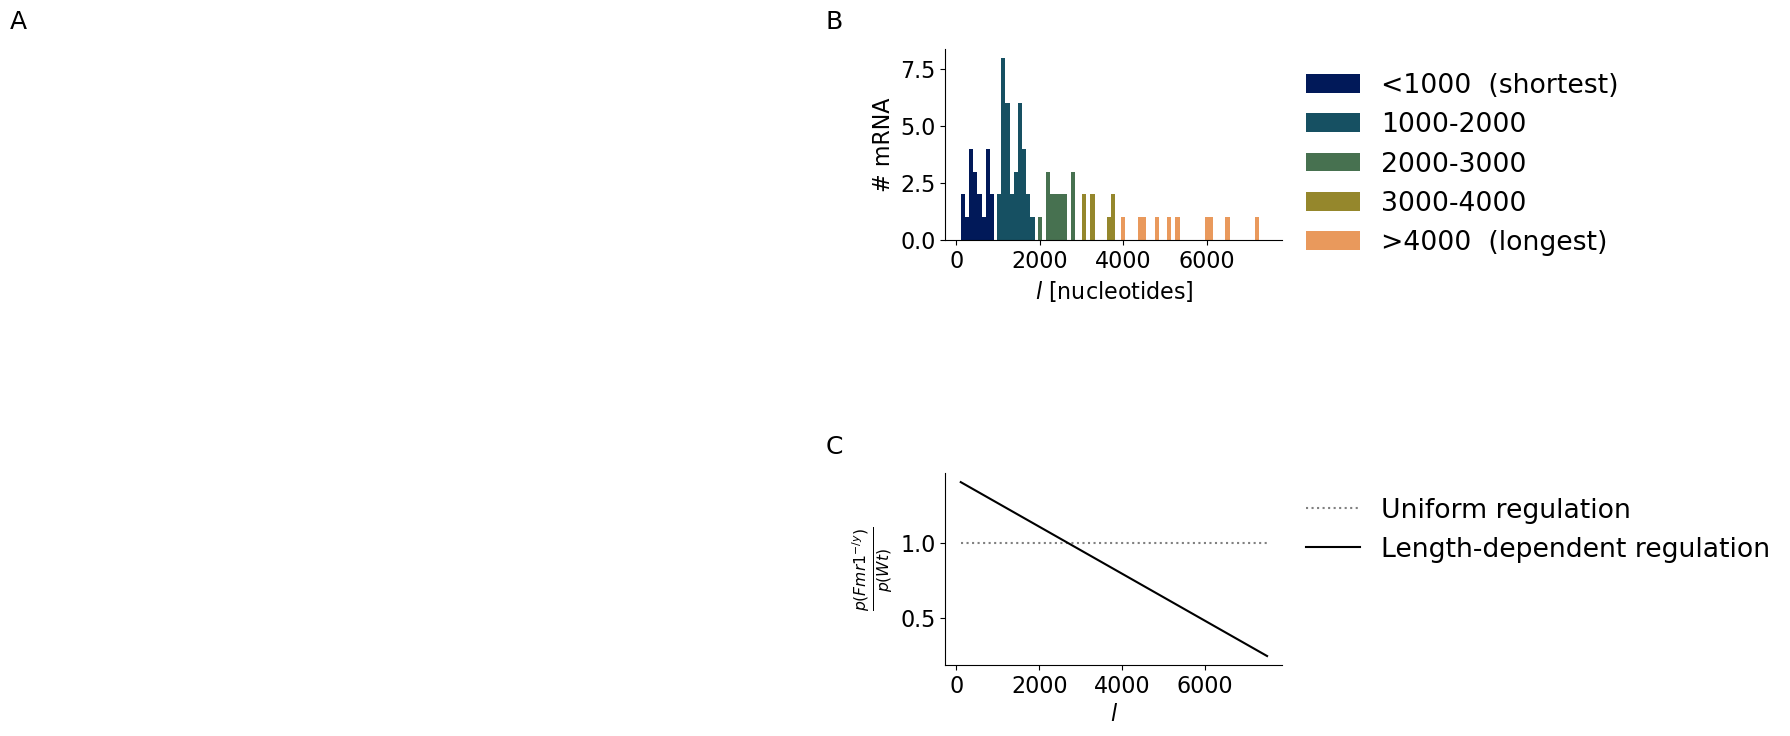

In [5]:
layout = '''
    AABB
    AABB
    AACC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [2,0.1,1,0.1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()

    
ax = fig.add_subplot(gs[0,2])
binwin = np.arange(l_samples[0],l_samples[s_1k[-1]],bin_width)
ax.hist(l_samples[s_1k], label = ['<1000  (shortest)'], color = palette[0], bins = binwin)
binwin = np.arange(l_samples[s_1k[-1]],l_samples[s_2k[-1]],bin_width)
ax.hist(l_samples[s_2k], color = palette[1], label = '1000-2000', bins = binwin)
binwin = np.arange(l_samples[s_2k[-1]],l_samples[s_3k[-1]],bin_width)
ax.hist(l_samples[s_3k], color = palette[2], label = '2000-3000', bins = binwin)
binwin = np.arange(l_samples[s_3k[-1]],l_samples[s_4k[-1]],bin_width)
ax.hist(l_samples[s_4k], color = palette[3], label = '3000-4000', bins = binwin)
binwin = np.arange(l_samples[s_4k[-1]],l_samples[b_4k[-1]],bin_width)
ax.hist(l_samples[b_4k], color = palette[4], label = '>4000  (longest)', bins = binwin)
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
ax.set_xlabel('$l$ [nucleotides]')
ax.set_ylabel('# mRNA')
clear_axes(ax)


ax = fig.add_subplot(gs[2,2])
ax.plot(l_samples, np.ones([l_samples.shape[0]]), color = 'grey',  linestyle = ':', label = 'Uniform regulation')
ax.plot([l_samples[0],l_samples[-1]], [1.4,0.25], color = 'k', label = 'Length-dependent regulation')
ax.set_ylabel('$\\frac{p(Fmr1^{-/y})}{p(Wt)}$')
ax.set_xlabel('$l$')
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)

plt.savefig(figures_path+'fig1_problem_description.pdf')
plt.show()